In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json

import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import builtins
_orig_print = builtins.print

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width = 300)


# Override print globally
def print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-02-12 17:19:05 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-02-12 17:19:05 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-02-12 17:19:05 __main__ INFO     transformers.__version__='5.0.0'


In [3]:
from src.models import ModelandTokenizer

# model_key = "allenai/Olmo-3-1125-32B"
# model_key = "allenai/Olmo-3.1-32B-Instruct"
# model_key = "allenai/Olmo-3.1-7B-RL-Zero-Code"

# model_key = "meta-llama/Llama-3.3-70B-Instruct"

# model_key = "deepseek-ai/deepseek-coder-33b-base"
# model_key = "deepseek-ai/DeepSeek-Coder-V2-Lite-Instruct"

# model_key = "openai/gpt-oss-20b"
# model_key = "openai/gpt-oss-120b" #! weird results. known issue.

# model_key = "Qwen/Qwen3-Coder-30B-A3B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-14B"
# model_key = "Qwen/Qwen2.5-Coder-14B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-32B"
model_key = "Qwen/Qwen2.5-Coder-32B-Instruct"
# model_key = "Qwen/Qwen2.5-72B"
# model_key = "Qwen/Qwen2.5-72B-Instruct"

# model_key = "bigcode/starcoder2-15b"

# model_key = "zai-org/GLM-4.7-Flash"

mt = ModelandTokenizer(
    model_key=model_key,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)

2026-02-12 17:19:09 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-02-12 17:19:09 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-12 17:19:09 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fcfa1f847a0>
2026-02-12 17:19:09 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fcfa18fbd50> server_hostname='huggingface.co' timeout=10
2026-02-12 17:19:09 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fcfa1ea67e0>
2026-02-12 17:19:09 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-12 17:19:09 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-12 17:19:09 http

Loading weights: 100%|██████████| 771/771 [00:22<00:00, 34.03it/s, Materializing param=model.norm.weight]                              


2026-02-12 17:19:36 httpcore.connection DEBUG    close.started
2026-02-12 17:19:36 httpcore.connection DEBUG    close.complete
2026-02-12 17:19:36 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-02-12 17:19:36 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fcfa190f4a0>
2026-02-12 17:19:36 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fcfa18fbd50> server_hostname='huggingface.co' timeout=10
2026-02-12 17:19:36 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fcf9e7f93a0>
2026-02-12 17:19:36 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-02-12 17:19:36 httpcore.http11 DEBUG    send_request_headers.complete
2026-02-12 17:19:36 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Get contrastive branches for one sample

In [4]:
from src.goals.eval import run_evaluation, pretty_print_eval_results
from src.goals.data import IncompleteCodeDataset
from src.tokens import prepare_input
from src.goals.data import CodeGenerations, Code
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch


SAMPLE_IDX = 11

eval_dataset = IncompleteCodeDataset.load_dataset()
print(eval_dataset[SAMPLE_IDX])

sample = eval_dataset[SAMPLE_IDX]
instruction = sample.instruction
unfinished_code = sample.code
function_name = sample.function_name or "func"
unit_tests = sample.unit_tests
prefills = []
for ptype, pfill_list in sample.prefills.items():
    prefills.extend([prefill, ptype] for prefill in pfill_list)


if supports_chat_template(mt):
    prompts = [
        apply_chat_template(
            mt=mt,
            user_query=instruction.strip(),
            incomplete_code=unfinished_code + prefill,
        )
        for prefill, ptype in prefills
    ]
else:
    prompts = [
        instruction + "<code>" + unfinished_code + prefill
        for (prefill, ptype) in prefills
    ]


inputs = prepare_input(
    prompts=prompts,
    tokenizer=mt,
)

output = generate_with_patch(
    mt=mt,
    inputs=inputs,
    n_gen_per_prompt=1,
    max_new_tokens=64,
    do_sample=False,
    remove_prefix=True,
)

results = CodeGenerations(
    sample=sample,
    generations=[
        Code(prefill=prefill, prefill_type=ptype, full_prompt=inp, lm_generation=out)
        for (prefill, ptype), inp, out in zip(prefills, prompts, output)
    ],
)

# print(f"[white]{str(results)}[/white]")

eval_results = run_evaluation(
    result = results,
    function_name=function_name,
    code_stop_tag="</code>",
)

# Print results in tabular format
pretty_print_eval_results(eval_results)

2026-02-12 17:19:37 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


IncompleteCodeSample(
    instruction='Write a function in python that checks if a list of integers is sorted in non-decreasing order.\n\n',
    code='def is_sorted(lst: list) -> bool:\n    return True if ',
    unit_tests=[([], True), ([1], True), ([1, 2, 3], True), ([3, 2, 1], False), ([1, 1, 1], True), ([1, 3, 2], False)],
    prefills={'aligned': ['', '(', 'lst', 'lst ==', 'lst == sorted(', 'sorted(', 'sorted(lst)', 'all(', '(lst'], 'adversarial': ['not', 'not (', 'lst +', '3', '1 +', 'any('], 'inconsequential': ['len(', 'bool(', 'True and', 'False or']},
    function_name='is_sorted'
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


True
False


"""def is_sorted(lst: list) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill                     ┃ Logic                                               ┃ Verdict      ┃ Unit Tests                                  ┃ Logs                                                ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ aligned: ""                 │ " all(lst <= lst for i in range(len(lst) - 1)) else │ PASSED       │                                             │                                                     │
│                             │ False"                                              │              │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "("                │ "(lst == sorted(lst)) else False"                   │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "lst"              │ "lst == sorted(lst) else False"                     │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "lst =="           │ "lst == sorted(lst) else False"                     │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "lst == sorted("   │ "lst == sorted( lst ) else False"                   │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "sorted("          │ "sorted( lst ) == lst else False"                   │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "sorted(lst)"      │ "sorted(lst) == lst else False"                     │ PASSED       │                                             │                                                     │
├─────────────────────────────┼─────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ aligned: "all("             │ "all(earlier <= later for earlier, later in         │ PASSED       │                                             │                                   

Summary: 17/19 passed, 2/19 failed

In [5]:
from dataclasses import dataclass, field
from dataclasses_json import DataClassJsonMixin
from typing import Any

@dataclass
class MCTSResult(DataClassJsonMixin):
    """
    Results from a single MCTS search + evaluation + contrastive sampling.
    Serializable via DataClassJsonMixin (.to_dict() / .from_dict()).
    
    The MCTS tree itself is not serialized (MCTSNode objects are not JSON-friendly).
    Instead, we store the contrastive pairs as text paths + outcome probs,
    and optionally save the tree as HTML via search.save_tree().
    """
    # Identification
    model_name: str = ""
    sample_idx: int = 0
    prefill: str = ""
    prefill_type: str = ""
    function_name: str = "func"
    
    # Prompt info
    prompt: str = ""                     # full prompt sent to LM
    prefix: str = ""                     # sample.code + prefill (for eval)
    
    # MCTS config & stats
    mcts_config: dict[str, Any] = field(default_factory=dict)
    mcts_stats: dict[str, Any] = field(default_factory=dict)
    
    # Evaluation counts {"green": N, "orange": N, "red": N, "total": N}
    eval_counts: dict[str, int] = field(default_factory=dict)
    
    # Contrastive pairs: depth (str key) -> list of {pos_path, neg_path, pos_probs, neg_probs}
    contrastive_pairs: dict[str, list[dict[str, Any]]] = field(default_factory=dict)
    
    # Sampling thresholds used
    sampling_config: dict[str, Any] = field(default_factory=dict)
    
    def save(self, filepath: str) -> None:
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        with open(filepath, "w") as f:
            json.dump(self.to_dict(), f, indent=2)
    
    @classmethod
    def load(cls, filepath: str) -> "MCTSResult":
        with open(filepath, "r") as f:
            return cls.from_dict(json.load(f))
    
    @property
    def total_pairs(self) -> int:
        return sum(len(p) for p in self.contrastive_pairs.values())
    
    @property
    def depths_with_pairs(self) -> list[int]:
        return sorted(int(d) for d in self.contrastive_pairs if self.contrastive_pairs[d])


# Quick test: round-trip serialization
_test = MCTSResult(model_name="test", sample_idx=0, prefill="x")
assert MCTSResult.from_dict(_test.to_dict()).model_name == "test"
print("MCTSResult serialization OK")

MCTSResult serialization OK

In [6]:
from src.goals.sampling import MCTSSearch
from src.goals.eval import evaluate_mcts_tree
from src.goals.probe import sample_multidepth_pairs, print_contrastive_pairs
from src.utils.env_utils import DEFAULT_RESULTS_DIR
from dataclasses import asdict

# --- Config ---
MCTS_ITERATIONS = 1500
MCTS_MAX_DEPTH = 20
MCTS_TOP_K = 10
MCTS_PROB_THRESHOLD = 0.01
DEPTH_FIRST = True

SAMPLING_CONFIG = dict(
    min_depth=1,
    max_depth=10,
    min_green_confidence=0.5,
    max_red_in_positive=0.3,
    min_red_confidence=0.5,
    max_green_in_negative=0.1,
    max_uncertain=0.5,
)

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(DEFAULT_RESULTS_DIR, "probe", model_short_name, f"sample_{SAMPLE_IDX}")
mcts_dir = os.path.join(save_dir, "MCTS")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(mcts_dir, exist_ok=True)
# --- Run MCTS + eval + contrastive sampling for each prefill ---
all_results: list[MCTSResult] = []

for prefill_idx, (prefill_val, prefill_type) in enumerate(prefills):
    _orig_print(f"\n{'='*60}")
    _orig_print(f"Prefill {prefill_idx}/{len(prefills)}: ({prefill_type}) {prefill_val!r}")
    _orig_print(f"{'='*60}")
    
    prompt = prompts[prefill_idx]
    prefix = sample.code + prefill_val
    
    # 1) MCTS search
    search = MCTSSearch(
        mt=mt,
        prompt=prompt,
        max_depth=MCTS_MAX_DEPTH,
        top_k=MCTS_TOP_K,
        prob_threshold=MCTS_PROB_THRESHOLD,
    )
    root = search.run(n_iterations=MCTS_ITERATIONS, depth_first=DEPTH_FIRST)
    
    # 2) Evaluate tree
    counts = evaluate_mcts_tree(
        root=search.root,
        prefix=prefix,
        unit_tests=sample.unit_tests,
        function_name=function_name,
        terminal_only=False,
    )
    _orig_print(f"  Eval counts: {counts}")
    
    # 3) Sample contrastive pairs
    pairs_by_depth = sample_multidepth_pairs(root=search.root, **SAMPLING_CONFIG)
    n_pairs = sum(len(p) for p in pairs_by_depth.values())
    _orig_print(f"  Contrastive pairs: {n_pairs}")
    
    # 4) Serialize contrastive pairs (MCTSNode -> text paths)
    serialized_pairs = {}
    for depth, pairs in pairs_by_depth.items():
        serialized_pairs[str(depth)] = [
            {
                "pos_path": pair.positive.get_path_text(),
                "neg_path": pair.negative.get_path_text(),
                "pos_probs": {"green": pair.pos_probs.green, "red": pair.pos_probs.red, "uncertain": pair.pos_probs.uncertain},
                "neg_probs": {"green": pair.neg_probs.green, "red": pair.neg_probs.red, "uncertain": pair.neg_probs.uncertain},
            }
            for pair in pairs
        ]
    
    # 5) Build result
    result = MCTSResult(
        model_name=model_short_name,
        sample_idx=SAMPLE_IDX,
        prefill=prefill_val,
        prefill_type=prefill_type,
        function_name=function_name,
        prompt=prompt,
        prefix=prefix,
        mcts_config=dict(
            iterations=MCTS_ITERATIONS, max_depth=MCTS_MAX_DEPTH,
            top_k=MCTS_TOP_K, prob_threshold=MCTS_PROB_THRESHOLD,
            depth_first=DEPTH_FIRST,
        ),
        mcts_stats=search.get_stats(),
        eval_counts=counts,
        contrastive_pairs=serialized_pairs,
        sampling_config=SAMPLING_CONFIG,
    )
    all_results.append(result)
    
    # 6) Save to disk
    safe_prefill_name = prefill_val.replace(" ", "_").replace("/", "_") or "empty"
    result_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}.json")
    result.save(result_path)
    
    # Also save tree HTML
    tree_path = os.path.join(mcts_dir, f"prefill_{prefill_idx}_{safe_prefill_name}_tree.html")
    search.save_tree(tree_path, show_colors=True)

print(f"\n[bold]Done! Saved {len(all_results)} results to {mcts_dir}[/bold]")
print(f"Total contrastive pairs across all prefills: {sum(r.total_pairs for r in all_results)}")


Prefill 0/19: (aligned) ''
2026-02-12 17:19:53 src.goals.sampling DEBUG    MCTS iteration 50/1500, total nodes: 93
2026-02-12 17:19:58 src.goals.sampling DEBUG    MCTS iteration 100/1500, total nodes: 163
2026-02-12 17:19:58 src.goals.sampling DEBUG    MCTS iteration 150/1500, total nodes: 163
2026-02-12 17:19:58 src.goals.sampling DEBUG    MCTS iteration 200/1500, total nodes: 163
2026-02-12 17:20:00 src.goals.sampling DEBUG    MCTS iteration 250/1500, total nodes: 181
2026-02-12 17:20:00 src.goals.sampling DEBUG    MCTS iteration 300/1500, total nodes: 181
2026-02-12 17:20:00 src.goals.sampling DEBUG    MCTS iteration 350/1500, total nodes: 181
2026-02-12 17:20:00 src.goals.sampling DEBUG    MCTS iteration 400/1500, total nodes: 181
2026-02-12 17:20:00 src.goals.sampling DEBUG    MCTS iteration 450/1500, total nodes: 181
2026-02-12 17:20:01 src.goals.sampling DEBUG    MCTS iteration 500/1500, total nodes: 202
2026-02-12 17:20:01 src.goals.sampling DEBUG    MCTS iteration 550/1500, t

Done! Saved 19 results to /disk/u/arnab/Codes/Projects/goals/results/probe/Qwen2.5-Coder-32B-Instruct/sample_11/MCTS

Total contrastive pairs across all prefills: 12579

## extract latents

In [7]:
@torch.inference_mode()
def get_last_token_latents_batch(
    mt: ModelandTokenizer,
    texts: list[str],
    layers: list[int] | None = None,
) -> dict[int, torch.Tensor]:
    """
    Extract residual stream hidden states at the last token position for a batch of inputs.
    
    Simplified and batched alternative to get_hs — no interventions, only grabs
    the last (non-padding) token's residual stream across specified layers.
    
    Each layer's output stays on its native GPU (no cross-device stacking).
    
    Args:
        mt: ModelandTokenizer instance
        texts: List of input strings
        layers: Layer indices to extract from. None = all layers.
    
    Returns:
        Dict mapping layer_idx -> Tensor of shape (batch, hidden_dim) on that layer's device.
    """
    if layers is None:
        layers = list(range(mt.n_layer))
    
    # Tokenize with left-padding so the last non-pad token is always at position -1
    inputs = prepare_input(prompts=texts, tokenizer=mt, padding_side="left")
    
    # Set up nnsight trace to capture layer outputs
    layer_saves = {}
    with mt.trace(inputs, scan=False):
        for layer_idx in layers:
            layer_name = mt.layer_name_format.format(layer_idx)
            module = mt
            for attr in layer_name.split("."):
                module = module[int(attr)] if attr.isdigit() else getattr(module, attr)
            output = module.output
            # Some architectures wrap output in a tuple
            if isinstance(output, tuple) or (hasattr(output, '__len__') and not hasattr(output, 'shape')):
                output = output[0]
            layer_saves[layer_idx] = output[:, -1, :].save()  # (batch, hidden_dim)
    
    # Return per-layer tensors, each staying on its native device
    return {l: layer_saves[l].float() for l in layers}


# Quick test
_test_hs = get_last_token_latents_batch(mt, [prompts[0], prompts[1]], layers=[0, mt.n_layer - 1])
for l, t in _test_hs.items():
    print(f"Layer {l}: shape={t.shape}, device={t.device}")
print(f"All layers for 1 input would give {mt.n_layer} tensors of shape (1, {mt.n_embd})")

Layer 0: shape=torch.Size([2, 5120]), device=cuda:0

Layer 63: shape=torch.Size([2, 5120]), device=cuda:7

All layers for 1 input would give 64 tensors of shape (1, 5120)

In [8]:
import random
from collections import Counter, defaultdict

# --- Config ---
UNIQUE_POSITIVE_SAMPLING = False  # If True, each unique positive node appears in only 1 pair
N_TRAIN_PAIRS = None            # Max training pairs after split. None = use all available.

# --- 1) Collect all contrastive pairs, tagged by prefill_idx ---

pair_records = []

for prefill_idx, result in enumerate(all_results):
    for depth_str, pairs in result.contrastive_pairs.items():
        for pair in pairs:
            pair_records.append({
                "prompt": result.prompt,
                "prefix": result.prefix,
                "pos_path": pair["pos_path"],
                "neg_path": pair["neg_path"],
                "depth": int(depth_str),
                "prefill_idx": prefill_idx,
                "prefill": result.prefill,
                "prefill_type": result.prefill_type,
            })

n_pairs_before_dedup = len(pair_records)
_orig_print(f"Total contrastive pair records (Cartesian product): {n_pairs_before_dedup}")

# --- 1b) Optional: unique positive sampling ---
# Each unique positive node (prefill_idx, pos_path) keeps only 1 randomly chosen pair.
# This prevents the same positive latent from appearing in multiple pairs.
if UNIQUE_POSITIVE_SAMPLING:
    random.seed(42)
    # Group pairs by (prefill_idx, pos_path)
    pos_groups: dict[tuple[int, str], list[int]] = defaultdict(list)
    for i, rec in enumerate(pair_records):
        pos_groups[(rec["prefill_idx"], rec["pos_path"])].append(i)
    
    # Keep one random pair per unique positive
    keep_indices = sorted(random.choice(indices) for indices in pos_groups.values())
    pair_records = [pair_records[i] for i in keep_indices]
    
    n_unique_pos = len(pos_groups)
    _orig_print(f"Unique positive sampling: {n_pairs_before_dedup} -> {len(pair_records)} pairs "
                f"({n_unique_pos} unique positive nodes, "
                f"{n_pairs_before_dedup / n_unique_pos:.1f}x avg Cartesian expansion)")

n_pairs_total = len(pair_records)
_orig_print(f"Pair records used: {n_pairs_total}")

# Show distribution by depth
depth_counts = Counter(r["depth"] for r in pair_records)
for d in sorted(depth_counts):
    _orig_print(f"  Depth {d}: {depth_counts[d]} pairs")

# --- 2) Tree/prefill-level train/test split ---
# Reserve entire trees for test. At least 1 of each prefill type in test.
# Only consider prefills that have >0 contrastive pairs.

# Count pairs per prefill
pairs_per_prefill: dict[int, int] = Counter(r["prefill_idx"] for r in pair_records)

# Group prefill indices by type, only those with pairs
prefill_type_to_indices: dict[str, list[int]] = defaultdict(list)
for idx, result in enumerate(all_results):
    if pairs_per_prefill.get(idx, 0) > 0:
        prefill_type_to_indices[result.prefill_type].append(idx)

random.seed(42)
test_prefill_set: set[int] = set()
for ptype, indices in prefill_type_to_indices.items():
    if len(indices) == 0:
        _orig_print(f"  WARNING: no prefills with pairs for type '{ptype}', skipping")
        continue
    if len(indices) == 1:
        # Only 1 prefill with pairs for this type — must keep it for train
        _orig_print(f"  WARNING: only 1 prefill with pairs for type '{ptype}' (idx={indices[0]}), keeping in train")
        continue
    test_prefill_set.add(random.choice(indices))

train_prefill_set = set(range(len(all_results))) - test_prefill_set

# Build pair-level indices from the prefill-level split
train_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in train_prefill_set]
test_idx = [i for i, rec in enumerate(pair_records) if rec["prefill_idx"] in test_prefill_set]

# --- 2b) Cap training pairs ---
# Shuffle train_idx first to ensure variety across prefills/depths, then truncate.
random.seed(42)
random.shuffle(train_idx)
n_train_before_cap = len(train_idx)
if N_TRAIN_PAIRS is not None and len(train_idx) > N_TRAIN_PAIRS:
    train_idx = train_idx[:N_TRAIN_PAIRS]

# --- Print split summary ---
_orig_print(f"\n{'='*60}")
_orig_print(f"Tree-level train/test split (no latent leakage)")
if UNIQUE_POSITIVE_SAMPLING:
    _orig_print(f"  + unique positive sampling (each pos node in 1 pair only)")
if N_TRAIN_PAIRS is not None:
    _orig_print(f"  + train cap: {N_TRAIN_PAIRS} (from {n_train_before_cap} available)")
else:
    _orig_print(f"  + train cap: None (using all {n_train_before_cap} available)")
_orig_print(f"{'='*60}")
_orig_print(f"Train prefills ({len(train_prefill_set)}):")
for idx in sorted(train_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"Test prefills ({len(test_prefill_set)}):")
for idx in sorted(test_prefill_set):
    r = all_results[idx]
    n = pairs_per_prefill.get(idx, 0)
    _orig_print(f"  [{idx:>2}] ({r.prefill_type:>16}) {r.prefill!r:<15} -> {n} pairs")

_orig_print(f"\nTrain pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")
if len(test_idx) == 0:
    _orig_print("WARNING: 0 test pairs! All prefill types may have <=1 prefill with pairs.")

Total contrastive pair records (Cartesian product): 12579
Pair records used: 12579
  Depth 1: 43 pairs
  Depth 2: 152 pairs
  Depth 3: 248 pairs
  Depth 4: 419 pairs
  Depth 5: 963 pairs
  Depth 6: 1588 pairs
  Depth 7: 2047 pairs
  Depth 8: 2482 pairs
  Depth 9: 2332 pairs
  Depth 10: 2305 pairs

Tree-level train/test split (no latent leakage)
  + train cap: None (using all 12249 available)
Train prefills (16):
  [ 1] (         aligned) '('             -> 309 pairs
  [ 2] (         aligned) 'lst'           -> 0 pairs
  [ 3] (         aligned) 'lst =='        -> 0 pairs
  [ 4] (         aligned) 'lst == sorted(' -> 192 pairs
  [ 5] (         aligned) 'sorted('       -> 566 pairs
  [ 6] (         aligned) 'sorted(lst)'   -> 0 pairs
  [ 7] (         aligned) 'all('          -> 0 pairs
  [ 8] (         aligned) '(lst'          -> 7 pairs
  [10] (     adversarial) 'not ('         -> 650 pairs
  [11] (     adversarial) 'lst +'         -> 439 pairs
  [12] (     adversarial) '3'             -

In [9]:
# --- 2) Extract latents for all contrastive pairs (batched) ---
# For each pair, we feed prompt + pos_path and prompt + neg_path,
# extract hidden states at last token position for all layers.
# Latents are stored per-layer, each on its native GPU.

LAYERS_TO_PROBE = list(range(mt.n_layer))  # all layers; narrow down later
BATCH_SIZE = 32  # number of texts per forward pass (adjust based on GPU memory)

# Build flat list of all texts to process
pos_texts = [rec["prompt"] + rec["pos_path"] for rec in pair_records]
neg_texts = [rec["prompt"] + rec["neg_path"] for rec in pair_records]
all_texts = pos_texts + neg_texts  # 2 * n_pairs texts total

n_total = len(all_texts)
n_pairs_total = len(pair_records)
_orig_print(f"Extracting latents for {n_total} texts ({n_pairs_total} pairs) in batches of {BATCH_SIZE}...")

# Accumulate per-layer: layer_idx -> list of (batch_size, hidden_dim) tensors
latents_by_layer: dict[int, list[torch.Tensor]] = {l: [] for l in LAYERS_TO_PROBE}

for batch_start in range(0, n_total, BATCH_SIZE):
    batch_texts = all_texts[batch_start : batch_start + BATCH_SIZE]
    if batch_start % (BATCH_SIZE * 10) == 0:
        _orig_print(f"  Batch {batch_start // BATCH_SIZE + 1}/{(n_total + BATCH_SIZE - 1) // BATCH_SIZE}...")
    
    batch_hs = get_last_token_latents_batch(mt, batch_texts, layers=LAYERS_TO_PROBE)
    for l in LAYERS_TO_PROBE:
        latents_by_layer[l].append(batch_hs[l])

# Concatenate per-layer: layer_idx -> (2*n_pairs, hidden_dim) on that layer's device
# Then split into pos/neg per layer
Z_pos_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs, hidden_dim)
Z_neg_by_layer: dict[int, torch.Tensor] = {}  # layer -> (n_pairs, hidden_dim)

for l in LAYERS_TO_PROBE:
    all_l = torch.cat(latents_by_layer[l], dim=0)  # (2*n_pairs, hidden_dim), same device
    Z_pos_by_layer[l] = all_l[:n_pairs_total]
    Z_neg_by_layer[l] = all_l[n_pairs_total:]

del latents_by_layer  # free the intermediate lists

# Print summary
_sample_layer = LAYERS_TO_PROBE[0]
print(f"Per-layer tensors: {len(Z_pos_by_layer)} layers")
print(f"  Layer {_sample_layer}: Z_pos {Z_pos_by_layer[_sample_layer].shape} on {Z_pos_by_layer[_sample_layer].device}")
_last_layer = LAYERS_TO_PROBE[-1]
print(f"  Layer {_last_layer}: Z_pos {Z_pos_by_layer[_last_layer].shape} on {Z_pos_by_layer[_last_layer].device}")

Extracting latents for 25158 texts (12579 pairs) in batches of 32...
  Batch 1/787...
  Batch 11/787...
  Batch 21/787...
  Batch 31/787...
  Batch 41/787...
  Batch 51/787...
  Batch 61/787...
  Batch 71/787...
  Batch 81/787...
  Batch 91/787...
  Batch 101/787...
  Batch 111/787...
  Batch 121/787...
  Batch 131/787...
  Batch 141/787...
  Batch 151/787...
  Batch 161/787...
  Batch 171/787...
  Batch 181/787...
  Batch 191/787...
  Batch 201/787...
  Batch 211/787...
  Batch 221/787...
  Batch 231/787...
  Batch 241/787...
  Batch 251/787...
  Batch 261/787...
  Batch 271/787...
  Batch 281/787...
  Batch 291/787...
  Batch 301/787...
  Batch 311/787...
  Batch 321/787...
  Batch 331/787...
  Batch 341/787...
  Batch 351/787...
  Batch 361/787...
  Batch 371/787...
  Batch 381/787...
  Batch 391/787...
  Batch 401/787...
  Batch 411/787...
  Batch 421/787...
  Batch 431/787...
  Batch 441/787...
  Batch 451/787...
  Batch 461/787...
  Batch 471/787...
  Batch 481/787...
  Batch 491

Per-layer tensors: 64 layers

Layer 0: Z_pos torch.Size([12579, 5120]) on cuda:0

Layer 63: Z_pos torch.Size([12579, 5120]) on cuda:7

## Train goal directions

In [10]:
# --- 3) Baseline: mean difference goal direction per layer ---
# For each layer l independently, find a direction v_l such that v_l · z⁺ > v_l · z⁻
# Baseline: v_l = mean(z⁺_l) - mean(z⁻_l), normalized.
# Each layer gets its own independent goal direction, stored on that layer's device.
# train_idx / test_idx are from tree-level split (no latent leakage).

n_pairs = n_pairs_total
n_layers = len(LAYERS_TO_PROBE)

_orig_print(f"Train pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")

# --- Compute and store goal direction per layer ---
goal_directions: dict[int, torch.Tensor] = {}   # layer -> (hidden_dim,) on layer's device
train_accuracies: dict[int, float] = {}
test_accuracies: dict[int, float] = {}

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]  # (n_pairs, hidden_dim) on layer's device
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    # Goal direction for this layer: mean difference on train set
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l = z_pos_train.mean(dim=0) - z_neg_train.mean(dim=0)
    v_l = v_l / (v_l.norm() + 1e-8)
    goal_directions[layer_idx] = v_l
    
    # Train accuracy: fraction of pairs where v_l · z⁺ > v_l · z⁻
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    train_accuracies[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    test_accuracies[layer_idx] = test_acc

print(f"\ngoal_directions: {len(goal_directions)} layers, each on its native device")
print(f"\nConstraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:")
print(f"{'Layer':>6} {'Train':>8} {'Test':>8} {'Device':>10}")
print(f"{'-----':>6} {'-----':>8} {'-----':>8} {'------':>10}")
for l in LAYERS_TO_PROBE:
    marker = " <--" if test_accuracies[l] >= 0.8 else ""
    _orig_print(f"{l:>6} {train_accuracies[l]:>8.3f} {test_accuracies[l]:>8.3f} {str(goal_directions[l].device):>10}{marker}")

Train pairs: 12249, Test pairs: 330


goal_directions: 64 layers, each on its native device

Constraint accuracy (v_l · z⁺ > v_l · z⁻) per layer:

Layer    Train     Test     Device

-----    -----    -----     ------

     0    0.852    0.652     cuda:0
     1    0.852    0.670     cuda:0
     2    0.825    0.630     cuda:0
     3    0.831    0.664     cuda:0
     4    0.863    0.685     cuda:0
     5    0.833    0.661     cuda:0
     6    0.835    0.658     cuda:1
     7    0.829    0.642     cuda:1
     8    0.826    0.645     cuda:1
     9    0.822    0.621     cuda:1
    10    0.823    0.621     cuda:1
    11    0.831    0.630     cuda:1
    12    0.838    0.642     cuda:1
    13    0.859    0.664     cuda:1
    14    0.867    0.645     cuda:1
    15    0.872    0.652     cuda:2
    16    0.905    0.673     cuda:2
    17    0.913    0.661     cuda:2
    18    0.914    0.673     cuda:2
    19    0.916    0.673     cuda:2
    20    0.916    0.639     cuda:2
    21    0.917    0.615     cuda:2
    22    0.917    0.627     cuda:2
    23    0.918    0.618     cuda:2
    24    0.917    0.627     cuda:3
    25    0.917    0.633     cuda:3
    26    0.918    0.645     cuda:3
    27    0.918    0.642    

In [11]:
# --- Contrastive objective (Schut et al. Section 4.1.2) ---
# Find v_l that satisfies v_l · z⁺ ≥ v_l · z⁻ + margin.
# Objective: min  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
# Setting both lambdas to 0 gives pure hinge loss (no regularization).

@torch.enable_grad()
def learn_contrastive_direction(
    z_pos: torch.Tensor,       # (n_pairs, hidden_dim) on some device
    z_neg: torch.Tensor,       # (n_pairs, hidden_dim) on same device
    l1_lambda: float = 0.0,
    l2_lambda: float = 1e-3,
    margin: float = 1.0,
    lr: float = 1e-2,
    n_steps: int = 1000,
    patience: int = 50,
) -> tuple[torch.Tensor, dict]:
    """
    Learn a goal direction via the contrastive objective.
    
    Minimizes:  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))
    
    - L1 encourages sparsity (neuron-basis assumption, strong).
    - L2 encourages small norm without basis assumptions.
    - Both at 0 = pure hinge loss, no regularization.
    
    Args:
        z_pos: Positive latents (n_pairs, hidden_dim)
        z_neg: Negative latents (n_pairs, hidden_dim)
        l1_lambda: L1 regularization strength (sparsity)
        l2_lambda: L2 regularization strength (norm penalty)
        margin: Hinge loss margin
        lr: Learning rate for Adam
        n_steps: Maximum optimization steps
        patience: Early stopping patience (steps without improvement)
    
    Returns:
        v: Normalized goal direction (hidden_dim,) on same device
        info: Dict with optimization stats
    """
    device = z_pos.device
    hidden_dim = z_pos.shape[1]
    
    # Precompute difference vectors
    delta = z_pos - z_neg  # (n_pairs, hidden_dim)
    
    # Initialize v with small random values
    v = torch.randn(hidden_dim, device=device, dtype=z_pos.dtype) * 0.01
    v.requires_grad_(True)
    
    optimizer = torch.optim.Adam([v], lr=lr)
    
    best_loss = float('inf')
    patience_counter = 0
    final_step = n_steps
    
    for step in range(n_steps):
        optimizer.zero_grad()
        
        scores = delta @ v                                    # (n_pairs,)
        hinge_loss = torch.clamp(margin - scores, min=0).mean()
        
        # Regularization terms (only computed if lambda > 0)
        reg_loss = torch.zeros(1, device=device, dtype=z_pos.dtype)
        if l1_lambda > 0:
            reg_loss = reg_loss + l1_lambda * v.abs().sum()
        if l2_lambda > 0:
            reg_loss = reg_loss + l2_lambda * (v @ v)         # ||v||₂²
        
        loss = hinge_loss + reg_loss.squeeze()
        
        loss.backward()
        optimizer.step()
        
        curr_loss = loss.item()
        if curr_loss < best_loss - 1e-6:
            best_loss = curr_loss
            patience_counter = 0
        else:
            patience_counter += 1
        
        if patience_counter >= patience:
            final_step = step + 1
            break
    
    with torch.no_grad():
        v_final = v.detach()
        v_norm = v_final.norm()
        v_normalized = v_final / (v_norm + 1e-8)
        
        # Stats
        scores_final = delta @ v_normalized
        constraint_sat = (scores_final > 0).float().mean().item()
        sparsity = (v_normalized.abs() < 1e-2).float().mean().item()
    
    return v_normalized, {
        "final_loss": best_loss,
        "steps": final_step,
        "constraint_satisfaction": constraint_sat,
        "sparsity": sparsity,
        "v_norm_pre_normalize": v_norm.item(),
    }


print("learn_contrastive_direction defined (with L1 + L2 regularization)")

learn_contrastive_direction defined (with L1 + L2 regularization)

In [12]:
# --- Run contrastive objective per layer ---
# Uses the same train/test split as the baseline.

L1_LAMBDA = 0.0     # sparsity (neuron-basis assumption); 0 = off
L2_LAMBDA = 1e-3    # norm penalty (basis-free); 0 = off
MARGIN = 1.0
LR = 1e-2
N_STEPS = 1000

contrastive_directions: dict[int, torch.Tensor] = {}
contrastive_train_accs: dict[int, float] = {}
contrastive_test_accs: dict[int, float] = {}
contrastive_infos: dict[int, dict] = {}

reg_desc = []
if L1_LAMBDA > 0: reg_desc.append(f"λ₁={L1_LAMBDA}")
if L2_LAMBDA > 0: reg_desc.append(f"λ₂={L2_LAMBDA}")
if not reg_desc: reg_desc.append("no regularization")
_orig_print(f"Learning contrastive directions for {n_layers} layers ({', '.join(reg_desc)}, margin={MARGIN})...")

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]
    
    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]
    
    v_l, info = learn_contrastive_direction(
        z_pos_train, z_neg_train,
        l1_lambda=L1_LAMBDA, l2_lambda=L2_LAMBDA,
        margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    contrastive_directions[layer_idx] = v_l
    contrastive_infos[layer_idx] = info
    
    # Train accuracy
    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    contrastive_train_accs[layer_idx] = train_acc
    
    # Test accuracy
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    contrastive_test_accs[layer_idx] = test_acc
    
    if layer_idx % 10 == 0:
        _orig_print(f"  Layer {layer_idx:>3}: test_acc={test_acc:.3f}, steps={info['steps']}, sparsity={info['sparsity']:.3f}")

# --- Print comparison table ---
print(f"\n[bold]Comparison: Mean Difference vs Contrastive ({', '.join(reg_desc)})[/bold]")
print(f"{'Layer':>6} {'MeanDiff':>10} {'Contrastive':>12} {'Δ':>8} {'Steps':>6} {'Sparsity':>9}")
print(f"{'-----':>6} {'--------':>10} {'-----------':>12} {'--':>8} {'-----':>6} {'--------':>9}")
for l in LAYERS_TO_PROBE:
    md_acc = test_accuracies[l]
    ct_acc = contrastive_test_accs[l]
    delta = ct_acc - md_acc
    steps = contrastive_infos[l]["steps"]
    sparsity = contrastive_infos[l]["sparsity"]
    marker = " <--" if ct_acc >= 0.8 else ""
    _orig_print(f"{l:>6} {md_acc:>10.3f} {ct_acc:>12.3f} {delta:>+8.3f} {steps:>6} {sparsity:>9.3f}{marker}")

Learning contrastive directions for 64 layers (λ₂=0.001, margin=1.0)...
  Layer   0: test_acc=0.888, steps=290, sparsity=0.575
  Layer  10: test_acc=0.991, steps=526, sparsity=0.553
  Layer  20: test_acc=0.933, steps=824, sparsity=0.544
  Layer  30: test_acc=0.988, steps=787, sparsity=0.548
  Layer  40: test_acc=0.988, steps=1000, sparsity=0.581
  Layer  50: test_acc=0.985, steps=1000, sparsity=0.530
  Layer  60: test_acc=0.994, steps=1000, sparsity=0.514


Comparison: Mean Difference vs Contrastive (λ₂=0.001)

Layer   MeanDiff  Contrastive        Δ  Steps  Sparsity

-----   --------  -----------       --  -----  --------

     0      0.652        0.888   +0.236    290     0.575 <--
     1      0.670        0.942   +0.273    514     0.544 <--
     2      0.630        0.964   +0.333    436     0.537 <--
     3      0.664        0.982   +0.318    539     0.540 <--
     4      0.685        0.979   +0.294    319     0.569 <--
     5      0.661        0.982   +0.321    526     0.554 <--
     6      0.658        0.985   +0.327    373     0.559 <--
     7      0.642        0.988   +0.345    520     0.554 <--
     8      0.645        0.973   +0.327    432     0.557 <--
     9      0.621        0.988   +0.367    304     0.555 <--
    10      0.621        0.991   +0.370    526     0.553 <--
    11      0.630        0.982   +0.352    590     0.567 <--
    12      0.642        0.991   +0.348    484     0.559 <--
    13      0.664        0.991   +0.327    655     0.546 <--
    14      0.645        0.994   +0.348    729     0.540 <--
    15      0.652        0.988   +0.336    641     0.568 <--
    16      0.673       

2026-02-12 17:56:02 matplotlib DEBUG    matplotlib data path: /disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/matplotlib/mpl-data
2026-02-12 17:56:02 matplotlib DEBUG    CONFIGDIR=/disk/u/arnab/.config/matplotlib
2026-02-12 17:56:02 matplotlib DEBUG    interactive is False
2026-02-12 17:56:02 matplotlib DEBUG    platform is linux
2026-02-12 17:56:02 matplotlib DEBUG    CACHEDIR=/disk/u/arnab/.cache/matplotlib
2026-02-12 17:56:02 matplotlib.font_manager DEBUG    Using fontManager instance from /disk/u/arnab/.cache/matplotlib/fontlist-v390.json
2026-02-12 17:56:03 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-12 17:56:03 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-02-12 17:56:03 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-02-12 17:56:03 matplotlib.font_mana

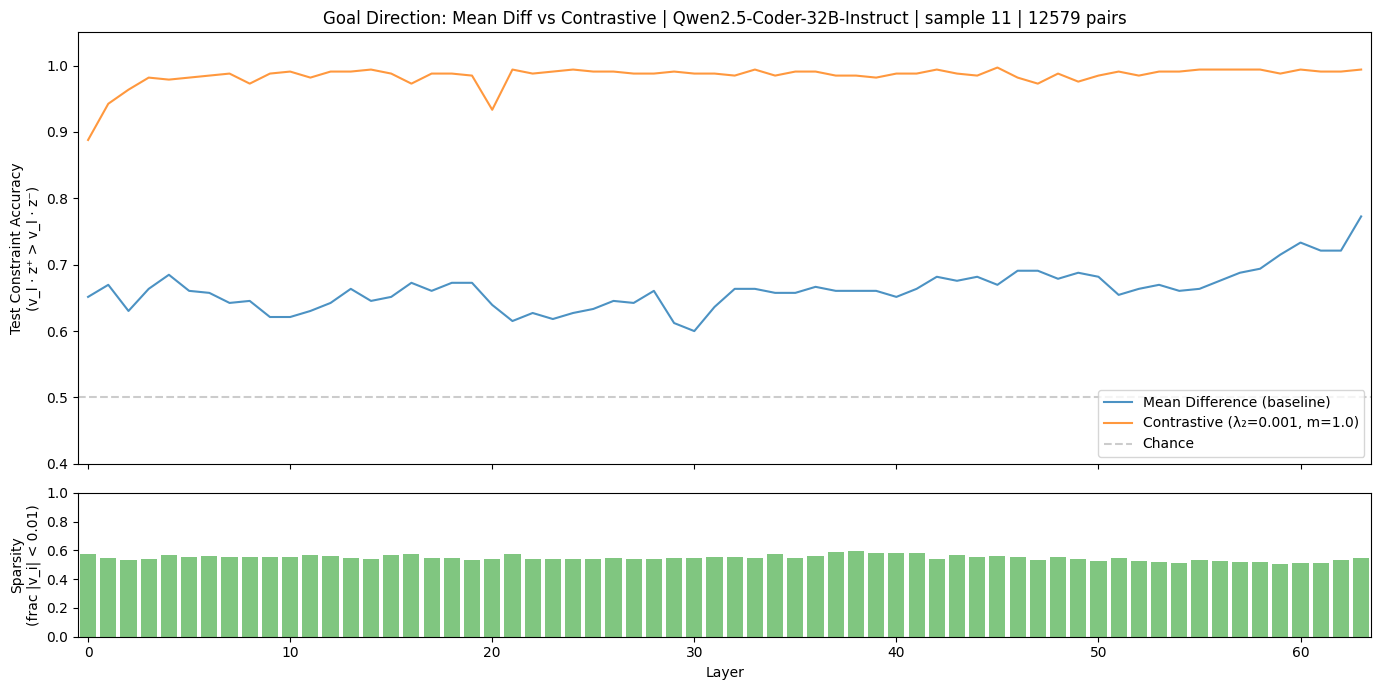

In [13]:
# --- Plot: Mean Difference vs Contrastive Objective ---
import matplotlib.pyplot as plt

layers_sorted = sorted(LAYERS_TO_PROBE)

md_test = [test_accuracies[l] for l in layers_sorted]
ct_test = [contrastive_test_accs[l] for l in layers_sorted]
ct_sparsity = [contrastive_infos[l]["sparsity"] for l in layers_sorted]

reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

# Top: accuracy comparison
ax = axes[0]
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy\n(v_l · z⁺ > v_l · z⁻)")
ax.set_title(f"Goal Direction: Mean Diff vs Contrastive | {model_short_name} | sample {SAMPLE_IDX} | {n_pairs} pairs")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

# Bottom: sparsity of contrastive directions
ax2 = axes[1]
ax2.bar(layers_sorted, ct_sparsity, alpha=0.6, color="tab:green", width=0.8)
ax2.set_xlabel("Layer")
ax2.set_ylabel("Sparsity\n(frac |v_i| < 0.01)")
ax2.set_ylim(0, 1)
ax2.set_xlim(layers_sorted[0] - 0.5, layers_sorted[-1] + 0.5)

plt.tight_layout()
plt.show()

In [14]:
torch.save(contrastive_directions, os.path.join(save_dir, "contrastive_directions.pt"))
torch.save(goal_directions, os.path.join(save_dir, "mean_diff_directions.pt"))

with open(os.path.join(save_dir, "contrastive_infos.json"), "w") as f:
    json.dump(contrastive_infos, f, indent=2)

with open(os.path.join(save_dir, "test_accuracies.json"), "w") as f:
    json.dump({
        "mean_diff": test_accuracies,
        "contrastive": contrastive_test_accs,
    }, f, indent=2)

## Test $\mathrm{causality}$

In [25]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset


SAMPLE_IDX = 11

eval_dataset = IncompleteCodeDataset.load_dataset()
sample = eval_dataset[SAMPLE_IDX]
print(sample)

prefill = "(3"
# prefill = "0 =="
# prefill = "1 +"
# prefill = "1 -"
# prefill = "1 - len(s)"
# prefill = "1"
# prefill = ""
# prefill = "(5"
# prefill = "("

if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip(),
        incomplete_code=sample.code + prefill,
    )
else:
    prompt = sample.instruction + "<code>" + sample.code + prefill

_orig_print(f"Prompt:\n{prompt}")

2026-02-12 18:46:10 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


IncompleteCodeSample(
    instruction='Write a function in python that checks if a list of integers is sorted in non-decreasing order.\n\n',
    code='def is_sorted(lst: list) -> bool:\n    return True if ',
    unit_tests=[([], True), ([1], True), ([1, 2, 3], True), ([3, 2, 1], False), ([1, 1, 1], True), ([1, 3, 2], False)],
    prefills={'aligned': ['', '(', 'lst', 'lst ==', 'lst == sorted(', 'sorted(', 'sorted(lst)', 'all(', '(lst'], 'adversarial': ['not', 'not (', 'lst +', '3', '1 +', 'any('], 'inconsequential': ['len(', 'bool(', 'True and', 'False or']},
    function_name='is_sorted'
)

Prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a list of integers is sorted in non-decreasing order.<|im_end|>
<|im_start|>assistant
<code>
def is_sorted(lst: list) -> bool:
    return True if (3


In [26]:
from src.functional import generate_with_patch, get_hs
from src.tokens import prepare_input

tokenized = prepare_input(
    prompts=prompt,
    tokenizer=mt,
)

hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(layer_name, -1) for layer_name in mt.layer_names],
)

orig_outputs = generate_with_patch(
    mt=mt,
    inputs=prompt,
    patches=None,
    do_sample=True,
    n_gen_per_prompt=100,
    remove_prefix=True,
    max_new_tokens=32,
)

# print("Original generations:")
# for gen in orig_outputs:
#     print(f'"  {gen}"')
#     print("-" * 50)

In [27]:
orig_generations = CodeGenerations(
    sample=sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="manual",
            full_prompt=prompt,
            lm_generation=gen,
        )
        for gen in orig_outputs
    ],
)

orig_eval_results = run_evaluation(
    result=orig_generations,
    function_name=sample.function_name,
    code_stop_tag="</code>",
)

pretty_print_eval_results(orig_eval_results)

"""def is_sorted(lst: list) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill      ┃ Logic                                                       ┃ Verdict      ┃ Unit Tests                                  ┃ Logs                                                       ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ manual: "(3" │ "(3 >= len(lst) or all(lst <= lst for i in range(len(lst) - │ FAILED       │ is_sorted([])=True ✓                        │                                                            │
│              │ 1))) else False"                                            │              │ is_sorted([1])=True ✓                       │                                                            │
│              │                                                             │              │ is_sorted([1, 2, 3])=True ✓                 │                                                            │
│              │                                                             │              │ is_sorted([3, 2, 1])=True, expected False ✗ │                                                            │
│              │                                                             │              │ is_sorted([1, 1, 1])=True ✓                 │                                                            │
│              │                                                             │              │ is_sorted([1, 3, 2])=True, expected False ✗ │                                                            │
├──────────────┼─────────────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼────────────────────────────────────────────────────────────┤
│ manual: "(3" │ "(3 == len(lst) and lst[0] <= lst[1] <= lst[2]) else all(x  │ SYNTAX_ERROR │                                             │ '(' was never closed (<string>, line 2)                    │
│              │ <= y for x, y in zip(lst,"                                  │              │                                             │ def is_sorted(lst: list) -> bool:                          │
│              │                                                             │              │                                             │     return True if (3 == len(lst) and lst[0] <= lst[1] <=  │
│              │                                                             │              │                                             │ lst[2]) else all(x <= y for x, y in zip(lst,               │
├──────────────┼─────────────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼────────────────────────────────────────────────────────────┤
│ manual: "(3" │ "(3 in lst and 2 in lst) else all(lst <= lst for i in       │ FAILED       │ is_sorted([])=True ✓                        │                                                            │
│              │ range(len(lst) - 1))"                                       │              │ is_sorted([1])=True ✓                       │                                                            │
│              │                                                             │              │ is_sorted([1, 2, 3])=True ✓                 │                                                            │
│              │                                                             │              │ is_sorted([3, 2, 1])=True, expected False ✗ │                                          

Summary: 12/100 passed, 88/100 failed

In [34]:
from src.functional import PatchSpec

model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "probe", model_short_name, f"sample_{SAMPLE_IDX}"
)

loaded_directions = torch.load(
    os.path.join(
        save_dir,
        # "contrastive_directions.pt",
        "mean_diff_directions.pt"
    )
)

layer_from = 45
layer_to = 55

#! seems to vary per task. probably related to the number of tokens being generated or processed (?)
coeff = 0.05

steer_directions = []

for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx]
    scaled_goal_dir = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())

    _orig_print(
        f"layer={layer_idx} >> |h_orig|={h_orig.norm()}, |goal_dir|={goal_dir.norm()}, |scaled|={scaled_goal_dir.norm()}"
    )

    steer_directions.append(
        PatchSpec(location=(layer_name, -1), patch=scaled_goal_dir, strategy="add")
    )


layer=45 >> |h_orig|=308.0, |goal_dir|=0.9999998807907104, |scaled|=15.40000057220459
layer=46 >> |h_orig|=322.0, |goal_dir|=1.0, |scaled|=16.100000381469727
layer=47 >> |h_orig|=356.0, |goal_dir|=1.0, |scaled|=17.80000114440918
layer=48 >> |h_orig|=386.0, |goal_dir|=1.0, |scaled|=19.30000114440918
layer=49 >> |h_orig|=428.0, |goal_dir|=0.9999999403953552, |scaled|=21.400001525878906
layer=50 >> |h_orig|=462.0, |goal_dir|=0.9999999403953552, |scaled|=23.100000381469727
layer=51 >> |h_orig|=516.0, |goal_dir|=0.9999999403953552, |scaled|=25.800003051757812
layer=52 >> |h_orig|=568.0, |goal_dir|=1.0, |scaled|=28.399999618530273
layer=53 >> |h_orig|=644.0, |goal_dir|=1.0, |scaled|=32.20000076293945
layer=54 >> |h_orig|=688.0, |goal_dir|=1.0, |scaled|=34.400001525878906


In [35]:
patched_outputs = generate_with_patch(
    mt=mt,
    inputs=prompt,
    patches=steer_directions,
    patch_strategy="add",
    patch_at_all_generations=True,
    do_sample= True,
    n_gen_per_prompt=100,
    remove_prefix=True,
    max_new_tokens=32,
)

# print("Patched generations:")
# for gen in patched_outputs:
#     print(f'"  {gen}"')
#     print("-" * 50)

In [36]:
patch_generations = CodeGenerations(
    sample=sample,
    generations=[
        Code(
            prefill=prefill,
            prefill_type="manual",
            full_prompt=prompt,
            lm_generation=gen,
        )
        for gen in patched_outputs
    ],
)

patch_eval_results = run_evaluation(
    result=patch_generations,
    function_name=sample.function_name,
    code_stop_tag="</code>",
)

pretty_print_eval_results(patch_eval_results)

"""def is_sorted(lst: list) -> bool:
    return True if """

                                                                                        Code Completion Results                                                                                         
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Prefill      ┃ Logic                                                       ┃ Verdict      ┃ Unit Tests                                  ┃ Logs                                                       ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ manual: "(3" │ "(32"                                                       │ SYNTAX_ERROR │                                             │ '(' was never closed (<string>, line 2)                    │
│              │                                                             │              │                                             │ def is_sorted(lst: list) -> bool:                          │
│              │                                                             │              │                                             │     return True if (32                                     │
├──────────────┼─────────────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼────────────────────────────────────────────────────────────┤
│ manual: "(3" │ "(3 * lst == sorted(lst)) else False"                       │ FAILED       │ is_sorted([])=True ✓                        │                                                            │
│              │                                                             │              │ is_sorted([1])=False, expected True ✗       │                                                            │
│              │                                                             │              │ is_sorted([1, 2, 3])=False, expected True ✗ │                                                            │
│              │                                                             │              │ is_sorted([3, 2, 1])=False ✓                │                                                            │
│              │                                                             │              │ is_sorted([1, 1, 1])=False, expected True ✗ │                                                            │
│              │                                                             │              │ is_sorted([1, 3, 2])=False ✓                │                                                            │
├──────────────┼─────────────────────────────────────────────────────────────┼──────────────┼─────────────────────────────────────────────┼────────────────────────────────────────────────────────────┤
│ manual: "(3" │ "(3 == len(lst)) else all(lst <= lst for i in               │ FAILED       │ is_sorted([])=True ✓                        │                                                            │
│              │ range(len(lst) - 1))"                                       │              │ is_sorted([1])=True ✓                       │                                                            │
│              │                                                             │              │ is_sorted([1, 2, 3])=True ✓                 │                                                            │
│              │                                                             │              │ is_sorted([3, 2, 1])=True, expected False ✗ │                                                            │
│              │                                                             │              │ is_sorted([1, 1, 1])=True ✓                 │                                          

Summary: 9/100 passed, 91/100 failed

In [37]:
from src.functional import logit_lens

for layer_idx in range(layer_from, layer_to):
    h = hs[(mt.layer_name_format.format(layer_idx), -1)]
    direction = loaded_directions[layer_idx].to(mt.dtype).to(h.device)
    direction = direction * (h.norm() / direction.norm())
    ll_goal = logit_lens(
        mt=mt,
        h=direction,
    )
    _orig_print(f"{layer_idx}: {[str(pred) for pred in ll_goal]}")

45: ['"zza"[46814] (p=0.026, logit=11.062)', '"灏"[122089] (p=0.016, logit=10.625)', '"大事"[106178] (p=0.014, logit=10.438)', '"辟"[103121] (p=0.014, logit=10.438)', '"_UNS"[33399] (p=0.014, logit=10.438)']
46: ['"大事"[106178] (p=0.037, logit=11.125)', '"utherford"[92994] (p=0.007, logit=9.500)', '"灏"[122089] (p=0.007, logit=9.438)', '"-ie"[87327] (p=0.007, logit=9.438)', '"_UNS"[33399] (p=0.006, logit=9.375)']
47: ['"_UNS"[33399] (p=0.037, logit=11.250)', '"大事"[106178] (p=0.017, logit=10.438)', '"钊"[119712] (p=0.012, logit=10.125)', '"HEL"[50712] (p=0.012, logit=10.125)', '"资源整合"[117480] (p=0.011, logit=10.000)']
48: ['"REEN"[13813] (p=0.033, logit=11.250)', '"_UNS"[33399] (p=0.019, logit=10.688)', '"HEL"[50712] (p=0.017, logit=10.625)', '"ToBounds"[51880] (p=0.016, logit=10.562)', '"":"""[62366] (p=0.014, logit=10.375)']
49: ['" FALSE"[7833] (p=0.024, logit=10.938)', '"_UNS"[33399] (p=0.020, logit=10.750)', '"ToBounds"[51880] (p=0.017, logit=10.562)', '"uco"[94414] (p=0.016, logit=10.500

In [22]:
# SAMPLE_IDX = 0

# eval_dataset = IncompleteCodeDataset.load_dataset()
# sample = eval_dataset[SAMPLE_IDX]
# print(sample)

In [23]:
# from src.goals.eval import evaluate_single_code

# code = """def is_odd(n):
#     return True if 1 + (n & 1) else False"""

# print(evaluate_single_code(
#     full_code=code,
#     function_name="is_odd",
#     unit_tests=sample.unit_tests
# ))


In [24]:
# def is_odd(n):
#     return True if 1 + (n & 1) else False

# is_odd(2)